# Dynamische Systeme und Chaos

Das Notebook führt durch die Grundbegriffe der nichtlinearen Dynamik: Phasenraum und Fixpunkte, Stabilität über Linearisierung und Lyapunov-Funktionen, Bifurkationen der logistischen Abbildung mit der Feigenbaum-Konstante, den Schmetterlingseffekt im Lorenz-System, das Spektrum der Lyapunov-Exponenten (Benettin-Verfahren mit QR-Zerlegung) und die fraktale Dimension seltsamer Attraktoren (Box-Counting und Kaplan-Yorke) an der Kochkurve und am Hénon-Attraktor.

Wie kann ein vollständig deterministisches System unvorhersagbar werden, und wie misst man das?

#### **Hintergrund**

Ein **dynamisches System** ist eine Regel, die aus dem heutigen Zustand den von morgen macht: ein Pendel, das Wetter, eine Tierpopulation, ein Stromkreis. Ist die Regel deterministisch, legt der Anfangszustand die ganze Zukunft fest. Lange nahm man an, dass man diese Zukunft dann auch vorhersagen kann, wenn man den Anfang nur genau genug kennt. Die nichtlineare Dynamik zeigt, dass das nicht stimmt: In **chaotischen** Systemen wächst jeder noch so kleine Messfehler exponentiell, und nach einer endlichen Zeit ist die Vorhersage wertlos, obwohl nirgends Zufall im Spiel ist.

Poincaré stieß 1890 beim Dreikörperproblem auf dieses Verhalten. Lorenz fand es 1963 in einem stark vereinfachten Wettermodell (der „Schmetterlingseffekt“), May 1976 in der einfachsten Populationsgleichung, und Feigenbaum entdeckte 1978, dass der Weg ins Chaos über Periodenverdopplungen universell ist. Mandelbrot gab den seltsamen Mengen, auf denen chaotische Bahnen leben, den Namen Fraktale. Heute misst man Chaos mit Lyapunov-Exponenten und fraktalen Dimensionen, in der Wettervorhersage (Ensembles), in der Himmelsmechanik, in Herzrhythmen und Lasern. Im maschinellen Lernen steckt derselbe Mechanismus in explodierenden und verschwindenden Gradienten rekurrenter Netze: Dort wird ebenfalls ein Produkt vieler Jacobi-Matrizen gebildet.

Landkarte:

- **Grundbegriffe**
  - Phasenraum, Fixpunkte, Lyapunov-Funktion (Exp. 1): Beim Pendel ohne Dämpfung gibt es geschlossene und offene Bahnen, getrennt durch die Separatrix; mit Dämpfung laufen alle Bahnen in den Fixpunkt, und die Energie fällt monoton.
- **Der Weg ins Chaos**
  - Logistische Abbildung (Exp. 2): Periodenverdopplungen rücken geometrisch zusammen (Feigenbaum-Konstante 4.669); dahinter ist der Lyapunov-Exponent positiv, bei $r = 4$ genau $\ln2$.
- **Chaos messen**
  - Schmetterlingseffekt (Exp. 3): Zwei Lorenz-Bahnen mit Abstand $10^{-9}$ trennen sich wie $e^{\lambda t}$; nach etwa 25 Zeiteinheiten ist jede Vorhersage verloren.
  - Lyapunov-Spektrum, Kaplan–Yorke-Dimension (Exp. 4): $\lambda = (0.90, 0, -14.57)$; die Summe ist die Divergenz $-13.67$, die Dimension des Attraktors 2.06.
- **Fraktale**
  - Box-Counting an Kochkurve und Hénon-Attraktor (Exp. 5): nicht ganzzahlige Dimensionen, $\ln4/\ln3$ für die Kochkurve.

Verwandte Notebooks: Die numerischen Integratoren und die Floquet-Theorie stehen in [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb), die Volumenänderung im Phasenraum ($\frac d{dt}\ln J = \nabla\cdot f$) in [Vektoranalysis](https://github.com/deltorobarba/science/blob/main/maths/vectorcalculus.ipynb), die Synchronisation als Bifurkation in [Komplexe Netzwerke](https://github.com/deltorobarba/science/blob/main/maths/complexnetworks.ipynb).

#### **Theorie**

##### *1. Dynamische Systeme und Phasenraum*

Ein Zustand $x$ liegt im **Phasenraum**, und eine Regel legt fest, wie er sich ändert: kontinuierlich als **Fluss** $\dot x = f(x)$ oder schrittweise als **Abbildung** $x_{n+1} = F(x_n)$. Beim Pendel ist der Phasenraum die Ebene aus Winkel und Winkelgeschwindigkeit; jeder Punkt legt die ganze Zukunft fest. Ist $f$ stetig differenzierbar, hat $\dot x = f(x)$ zu jedem Startpunkt genau eine Lösung (**Satz von Picard–Lindelöf**). Deshalb schneiden sich Trajektorien nie: Im Schnittpunkt hätten zwei Bahnen denselben Zustand und damit dieselbe Zukunft. In der Ebene kann eine beschränkte Bahn deshalb nur zu einem Fixpunkt oder einem geschlossenen Zyklus laufen (**Satz von Poincaré–Bendixson**); Chaos braucht in Flüssen mindestens drei Dimensionen. Bei Abbildungen reicht schon eine, weil Sprünge keine stetige Kurve bilden müssen.

##### *2. Fixpunkte und Stabilität*

Ein **Fixpunkt** erfüllt $f(x^\ast) = 0$ (bzw. $F(x^\ast) = x^\ast$). Er ist **stabil**, wenn Bahnen in seiner Nähe dort bleiben, und **asymptotisch stabil**, wenn sie zu ihm laufen. Zwei Wege, das zu prüfen:
- **Linearisierung:** Mit $x = x^\ast + \delta x$ ist $\dot{\delta x}\approx J\,\delta x$ mit der **Jacobi-Matrix** $J_{ij} = \partial f_i/\partial x_j$ am Fixpunkt; die Lösung ist eine Summe von Termen $e^{\mu_kt}$ mit den Eigenwerten $\mu_k$ von $J$. Haben alle negativen Realteil, ist der Fixpunkt asymptotisch stabil, ist einer positiv, instabil. Komplexe Eigenwerte bedeuten **Spiralen**, reelle mit verschiedenen Vorzeichen einen **Sattel**. Solange kein Realteil null ist, sieht der nichtlineare Fluss nahe dem Fixpunkt aus wie der lineare (**Satz von Hartman–Grobman**). Bei Abbildungen ist ein Fixpunkt stabil, wenn alle Eigenwerte (in einer Dimension $\vert F'(x^\ast)\vert$) kleiner als 1 sind, denn ein kleiner Fehler wird pro Schritt damit multipliziert.
- **Lyapunov-Funktion:** eine Art Energie $V(x)$ mit $V(x^\ast) = 0$, $V>0$ sonst und $\dot V = \nabla V\cdot f\leq0$ entlang der Bahnen. Gibt es sie, ist $x^\ast$ stabil, ohne dass man die Gleichung löst. Beim gedämpften Pendel $\ddot\theta = -\sin\theta - \gamma\dot\theta$ ist $V = \tfrac12\dot\theta^2 + 1 - \cos\theta$ eine solche Funktion: $\dot V = -\gamma\dot\theta^2\leq0$.

Ohne Dämpfung ist $V$ erhalten, und die Bahnen sind die Höhenlinien von $V$: geschlossene Kurven (Schwingen), offene Kurven (Überschlagen) und dazwischen die **Separatrix** durch die Sattelpunkte $\theta = \pm\pi$.

##### *3. Attraktoren und Bifurkationen: die logistische Abbildung*

Gedämpfte Systeme ziehen sich auf einen **Attraktor** zusammen: einen Fixpunkt, einen **Grenzzyklus** oder eine kompliziertere Menge. Ändert man einen Parameter, kann sich die Art des Attraktors plötzlich ändern, eine **Bifurkation**. Das Standardbeispiel ist die **logistische Abbildung** $x_{n+1} = r\,x_n(1 - x_n)$, ein Modell einer Population mit begrenzter Nahrung. Ihre Fixpunkte sind 0 und $x^\ast = 1 - 1/r$ mit $F'(x^\ast) = 2 - r$, stabil für $1<r<3$. Bei $r = 3$ wird $F'(x^\ast) = -1$: Ein Fehler springt mit gleicher Größe hin und her, und es entsteht ein Zyklus der Periode 2 (**Periodenverdopplung**). Dasselbe wiederholt sich für die zweifach angewandte Abbildung, und so weiter: Periode 4, 8, 16, … Die Parameter $r_n$ der Verdopplungen rücken geometrisch zusammen,
$$\delta = \lim_{n\to\infty}\frac{r_n - r_{n-1}}{r_{n+1} - r_n} = 4.6692\ldots,$$
und häufen sich bei $r_\infty\approx3.5699$, dem Beginn des Chaos. Die **Feigenbaum-Konstante** $\delta$ ist für alle glatten Abbildungen mit einem quadratischen Maximum dieselbe (Feigenbaum 1978). Bequemer zu berechnen sind die **superstabilen** Parameter $R_n$, bei denen $x = \tfrac12$ (wo $F' = 0$) selbst auf dem $2^n$-Zyklus liegt; ihre Abstände haben dasselbe Verhältnis. Im chaotischen Bereich liegen **Fenster** periodischen Verhaltens, das größte mit Periode 3 bei $r\approx3.83$.

##### *4. Chaos und Lyapunov-Exponenten*

Ein System ist **chaotisch**, wenn es deterministisch und beschränkt ist und trotzdem empfindlich von den Anfangsbedingungen abhängt: Zwei beliebig nahe Startpunkte entfernen sich exponentiell, $\vert\delta x(t)\vert\approx\vert\delta x(0)\vert\,e^{\lambda t}$. Der größte **Lyapunov-Exponent** $\lambda$ misst diese Rate. Ist er positiv, ist jede Vorhersage nach einer Zeit von der Größe $\frac1\lambda\ln\frac{\text{Toleranz}}{\text{Anfangsfehler}}$ wertlos, der **Schmetterlingseffekt** (Lorenz 1963). Bei einer Abbildung wird ein kleiner Fehler nach $n$ Schritten mit dem Produkt der Ableitungen entlang der Bahn multipliziert; logarithmiert und gemittelt:
$$\lambda = \lim_{n\to\infty}\frac1n\sum_{k=0}^{n-1}\ln\vert F'(x_k)\vert .$$
Bei $r = 4$ macht die Substitution $x = \sin^2(\pi y/2)$ aus der logistischen Abbildung die **Zeltabbildung** $y\mapsto1 - \vert1 - 2y\vert$ mit Steigung vom Betrag 2; deshalb ist $\lambda = \ln2$ genau: Pro Schritt geht ein Bit Information über den Anfangszustand verloren. Lyapunov-Funktion und Lyapunov-Exponent gehen auf denselben Mathematiker zurück, meinen aber Verschiedenes: Die eine beweist Stabilität, der andere misst Instabilität.

##### *5. Das Lorenz-System und das Lyapunov-Spektrum*

$$\dot x = \sigma(y - x),\qquad\dot y = x(\rho - z) - y,\qquad\dot z = xy - \beta z,$$
mit den klassischen Werten $\sigma = 10$, $\rho = 28$, $\beta = 8/3$, ein stark vereinfachtes Modell der Konvektion in der Atmosphäre. Ein kleines Volumen im Phasenraum ändert sich wie $\dot V = (\nabla\cdot f)\,V$, und hier ist $\nabla\cdot f = -\sigma - 1 - \beta = -13.67$: Jedes Volumen schrumpft wie $e^{-13.67t}$, der Attraktor hat das Volumen null.

Ein System im $n$-dimensionalen Raum hat $n$ Lyapunov-Exponenten $\lambda_1\geq\lambda_2\geq\dots$, das **Lyapunov-Spektrum**: die mittleren Wachstumsraten von Längen, Flächen, Volumina. Ihre Summe ist die mittlere Divergenz, und bei einem Fluss ist einer immer null, weil eine Störung entlang der Bahn nur eine Zeitverschiebung ist. Berechnet wird das Spektrum mit dem **Benettin-Verfahren**: Man integriert die Bahn zusammen mit Störungsvektoren, die sich nach $\dot{\delta x} = J(x(t))\,\delta x$ entwickeln, und orthonormiert sie regelmäßig mit einer **QR-Zerlegung**, weil sonst alle in die Richtung des stärksten Wachstums kippen. Die Diagonale $R_{ii}$ gibt an, um welchen Faktor die $i$-te Richtung gewachsen ist; $\lambda_i = \lim\frac1T\sum_k\ln\vert R_{ii}^{(k)}\vert$.

##### *6. Seltsame Attraktoren und Fraktale*

In dissipativen chaotischen Systemen schrumpft jedes Volumen, und trotzdem laufen Bahnen auseinander. Beides zusammen geht nur, wenn der Attraktor in einer Richtung gestreckt und in einer anderen gefaltet wird, immer wieder. Es entsteht ein **seltsamer Attraktor**: eine Menge ohne Volumen mit Struktur auf allen Skalen, ein **Fraktal**, dessen Dimension keine ganze Zahl ist.
- **Box-Counting-Dimension:** Bedeckt man die Menge mit Kästchen der Kantenlänge $\varepsilon$ und braucht $N(\varepsilon)$ davon, ist $D_0 = \lim_{\varepsilon\to0}\ln N(\varepsilon)/\ln(1/\varepsilon)$. Eine Linie hat $D = 1$, eine Fläche $D = 2$. Die **Kochkurve** ersetzt jede Strecke durch vier Strecken von einem Drittel der Länge; mit $\varepsilon\to\varepsilon/3$ wird $N\to4N$, also $D = \ln4/\ln3 = 1.2619$.
- **Kaplan–Yorke-Dimension:** Sei $j$ die größte Zahl mit $\lambda_1 + \dots + \lambda_j\geq0$; dann ist $D_{KY} = j + (\lambda_1 + \dots + \lambda_j)/\vert\lambda_{j+1}\vert$. In $j$ Richtungen wächst ein Volumen, in Richtung $j + 1$ schrumpft es, und der Bruch sagt, wie viel von dieser Richtung der Attraktor noch ausfüllt.
- **Hénon-Abbildung:** $x_{n+1} = 1 - ax_n^2 + y_n$, $y_{n+1} = bx_n$, mit $a = 1.4$, $b = 0.3$ ein zweidimensionales Modell eines seltsamen Attraktors. Ihre Jacobi-Determinante ist überall $-b$: Flächen schrumpfen pro Schritt um den Faktor 0.3, also ist $\lambda_1 + \lambda_2 = \ln0.3$.

#### **Code**

Gemeinsame Funktionen: ein Runge-Kutta-Schritt vierter Ordnung für Systeme, die logistische Abbildung, das Lorenz-System mit seiner Jacobi-Matrix und eine Box-Counting-Funktion.

In [1]:
# Alles hier (numpy, scipy, matplotlib) ist in Colab vorinstalliert
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

def rk4_step(f, x, dt):
    k1 = f(x)
    k2 = f(x + dt / 2 * k1)
    k3 = f(x + dt / 2 * k2)
    k4 = f(x + dt * k3)
    return x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

logistic = lambda r, x: r * x * (1 - x)

SIGMA, RHO, BETA = 10.0, 28.0, 8.0 / 3.0
def lorenz(s):
    x, y, z = s
    return np.array([SIGMA * (y - x), x * (RHO - z) - y, x * y - BETA * z])

def lorenz_jacobian(s):
    x, y, z = s
    return np.array([[-SIGMA, SIGMA, 0.0], [RHO - z, -1.0, -x], [y, x, -BETA]])

def box_counting(points, epsilons, shift=0.37):
    """Anzahl der belegten Kästchen der Kantenlänge ε für jede ε (Punkte als Array (N, 2)).
    Das Gitter ist um shift·ε verschoben, damit keine Ecken der Menge genau auf Kästchenrändern liegen."""
    p = (points - points.min(axis=0)) / np.ptp(points, axis=0).max()          # in das Einheitsquadrat
    return np.array([len(np.unique(np.floor((p + shift * eps) / eps).astype(np.int64), axis=0)) for eps in epsilons])

print("Funktionen bereit")

Funktionen bereit


#### **Experimente**

##### *1. Phasenraum des Pendels und eine Lyapunov-Funktion*

Wie sieht der Phasenraum eines Pendels aus, und fällt seine Energie bei Dämpfung entlang jeder Trajektorie? Vorher vorhersagen: Welche Eigenwerte hat die Jacobi-Matrix am oberen Fixpunkt $\theta = \pi$, und was bedeuten sie?

Ohne Dämpfung werden die Höhenlinien der Energie $V$ gezeichnet; sie sind die Bahnen. Mit Dämpfung $\gamma = 0.3$ werden drei Bahnen aus der Ruhe bei $\theta_0 = 1.0$, 2.5 und 3.1 integriert und die Energie entlang jeder Bahn aufgetragen. Dazu kommen die Eigenwerte der Jacobi-Matrix an den beiden Fixpunkten.

**Hintergrund & Fachbegriffe:**
- **Phasenraum des Pendels:** die Ebene aus Winkel $\theta$ und Winkelgeschwindigkeit $\dot\theta$. Jeder Punkt ist ein vollständiger Zustand, jede Kurve eine mögliche Bewegung.
- **Fixpunkt:** ein Zustand, der sich nicht ändert: das hängende Pendel ($\theta = 0$, stabil) und das auf dem Kopf stehende ($\theta = \pm\pi$, instabil).
- **Separatrix:** die Bahn, die genau in den instabilen Fixpunkt hinein- und wieder herausläuft. Sie trennt das Hin- und Herschwingen vom Überschlagen.
- **Spirale und Sattel:** Am Fixpunkt geben die Eigenwerte der Jacobi-Matrix das Verhalten in der Nähe: komplex mit negativem Realteil eine Spirale nach innen, reell mit verschiedenen Vorzeichen einen Sattel.
- **Lyapunov-Funktion:** eine Größe, die entlang jeder Bahn nicht zunimmt; hier die Energie $V = \tfrac12\dot\theta^2 + 1 - \cos\theta$ mit $\dot V = -\gamma\dot\theta^2$.

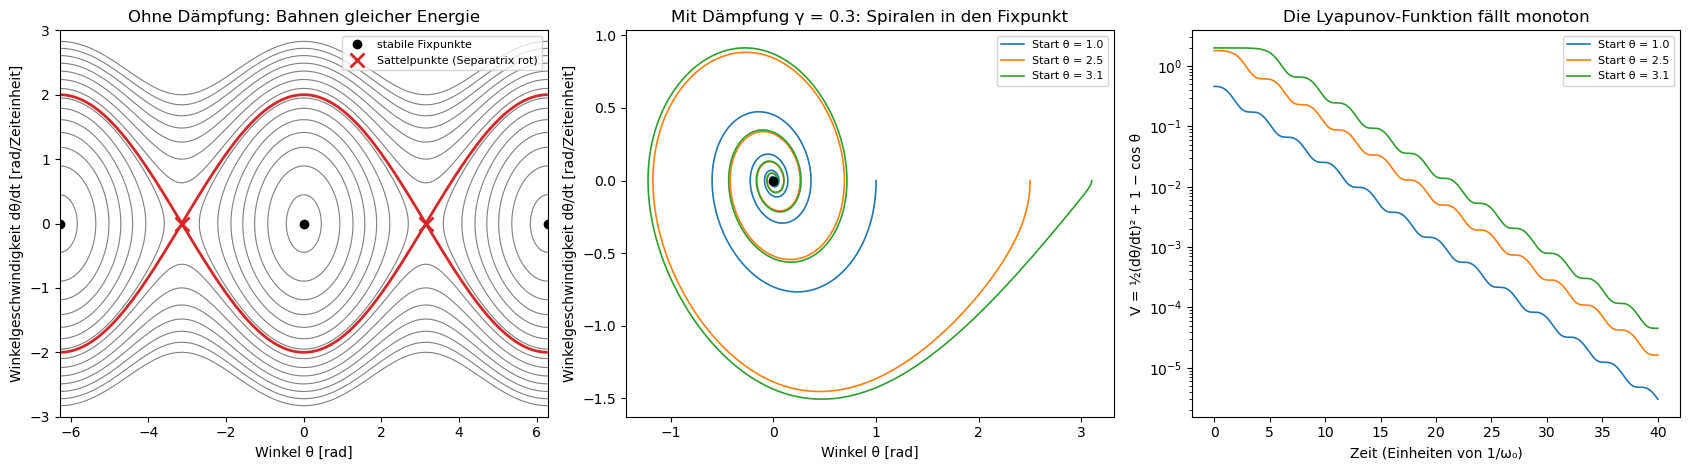

Eigenwerte am Fixpunkt θ = 0: [-0.15+0.989j -0.15-0.989j]  (komplex, Realteil < 0: stabile Spirale)
Eigenwerte am Fixpunkt θ = π: [ 0.861 -1.161]  (reell, verschiedene Vorzeichen: Sattel)
Größte Zunahme von V zwischen zwei Zeitpunkten: -1.2e-11 (≤ 0 bis auf Rundung)


In [2]:
GAMMA = 0.3
pend = lambda g: (lambda t, s: [s[1], -np.sin(s[0]) - g * s[1]])
V = lambda s: 0.5 * s[1] ** 2 + 1 - np.cos(s[0])        # Energie = Lyapunov-Funktion

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
TH, OM = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 400), np.linspace(-3, 3, 300))
axes[0].contour(TH, OM, 0.5 * OM ** 2 + 1 - np.cos(TH), levels=np.linspace(0.1, 4, 14), colors="grey", linewidths=0.8)
axes[0].contour(TH, OM, 0.5 * OM ** 2 + 1 - np.cos(TH), levels=[2.0], colors="tab:red", linewidths=2)
axes[0].plot([0, 2 * np.pi, -2 * np.pi], [0, 0, 0], "o", c="black", label="stabile Fixpunkte")
axes[0].plot([-np.pi, np.pi], [0, 0], "x", c="tab:red", ms=10, mew=2, label="Sattelpunkte (Separatrix rot)")
axes[0].set_title("Ohne Dämpfung: Bahnen gleicher Energie")
for th0 in [1.0, 2.5, 3.1]:
    sol = solve_ivp(pend(GAMMA), [0, 40], [th0, 0.0], max_step=0.02)
    axes[1].plot(sol.y[0], sol.y[1], lw=1.2, label=f"Start θ = {th0}")
    axes[2].semilogy(sol.t, V(sol.y), lw=1.2, label=f"Start θ = {th0}")
axes[1].plot(0, 0, "o", c="black")
axes[1].set_title(f"Mit Dämpfung γ = {GAMMA}: Spiralen in den Fixpunkt")
for ax in axes[:2]:
    ax.set_xlabel("Winkel θ [rad]")
    ax.set_ylabel("Winkelgeschwindigkeit dθ/dt [rad/Zeiteinheit]")
    ax.legend(fontsize=8)
axes[2].set_xlabel("Zeit (Einheiten von 1/ω₀)")
axes[2].set_ylabel("V = ½(dθ/dt)² + 1 − cos θ")
axes[2].set_title("Die Lyapunov-Funktion fällt monoton")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

J0 = np.array([[0, 1], [-1, -GAMMA]]); Jpi = np.array([[0, 1], [1, -GAMMA]])
print(f"Eigenwerte am Fixpunkt θ = 0: {np.round(np.linalg.eigvals(J0), 3)}  (komplex, Realteil < 0: stabile Spirale)")
print(f"Eigenwerte am Fixpunkt θ = π: {np.round(np.linalg.eigvals(Jpi), 3)}  (reell, verschiedene Vorzeichen: Sattel)")
sol = solve_ivp(pend(GAMMA), [0, 40], [2.5, 0.0], max_step=0.02)
print(f"Größte Zunahme von V zwischen zwei Zeitpunkten: {np.max(np.diff(V(sol.y))):.1e} (≤ 0 bis auf Rundung)")

* Das **linke Bild** zeigt die Bahnen ohne Dämpfung. Um die stabilen Fixpunkte (schwarz, bei $0$ und $\pm2\pi$) liegen geschlossene Kurven: Das Pendel schwingt hin und her. Oben und unten verlaufen offene, gewellte Kurven: Es überschlägt sich immer in dieselbe Richtung. Die rote Separatrix läuft durch die Sattelpunkte bei $\theta = \pm\pi$ und trennt beide Bereiche.
* Das **mittlere Bild** zeigt drei gedämpfte Bahnen: Alle spiralen in den Fixpunkt $(0, 0)$. Die Bahn, die bei $\theta_0 = 3.1$ fast auf dem Kopf startet, verharrt erst lange oben und schwingt dann weit aus. Das **rechte Bild** zeigt die Energie entlang der Bahnen auf logarithmischer Skala: Sie fällt treppenartig, schnell dort, wo das Pendel schnell ist ($\dot V = -\gamma\dot\theta^2$), und flach an den Umkehrpunkten, wo $\dot\theta = 0$ ist. Im Mittel fällt sie wie $e^{-\gamma t}$.
* Die **Ausgabe** gibt die Eigenwerte: bei $\theta = 0$ das Paar $-0.15\pm0.989i$ (komplex, negativer Realteil: stabile Spirale), bei $\theta = \pi$ die Werte $0.861$ und $-1.161$ (reell, verschiedene Vorzeichen: Sattel). Die größte Zunahme von $V$ zwischen zwei Zeitpunkten ist $-1.2\cdot10^{-11}$: $V$ nimmt nie zu, der Fixpunkt ist stabil.

##### *2. Die logistische Abbildung: Bifurkationen und Lyapunov-Exponent*

Wie wird aus einem Fixpunkt durch wiederholte Periodenverdopplung Chaos, und wo ist der Lyapunov-Exponent positiv? Vorher vorhersagen: Welchen Wert hat der Lyapunov-Exponent genau an einer Periodenverdopplung?

Für jeden Wert von $r$ zwischen 2.5 und 4 (Schritt 0.0005) läuft die Abbildung 1000 Schritte ein; die nächsten 300 Werte zeigen den Attraktor. Der Lyapunov-Exponent ist der Mittelwert von $\ln\vert r(1 - 2x)\vert$ über 2000 Schritte (Abschnitt 4 der Theorie). Die superstabilen Parameter $R_n$ werden mit einem Nullstellenverfahren bestimmt.

**Hintergrund & Fachbegriffe:**
- **Bifurkationsdiagramm:** Für jeden Parameterwert zeigt es die Werte, die das System auf Dauer annimmt. Ein Punkt pro $r$ heißt Fixpunkt, zwei heißt Periode 2, ein Band heißt Chaos.
- **Periodenverdopplung:** An einer Bifurkation wird ein Zyklus der Periode $p$ instabil, und ein Zyklus der Periode $2p$ übernimmt.
- **Feigenbaum-Konstante:** Das Verhältnis aufeinanderfolgender Abstände der Verdopplungen geht gegen $\delta = 4.6692$, für alle Abbildungen mit einem glatten, quadratischen Maximum.
- **Superstabil:** ein Parameter, bei dem der Punkt mit $F' = 0$ auf dem Zyklus liegt; dort wird ein Fehler sofort ausgelöscht, und der Lyapunov-Exponent ist $-\infty$.
- **Periodisches Fenster:** ein Parameterbereich mitten im Chaos, in dem wieder ein stabiler Zyklus existiert; das größte hat Periode 3.

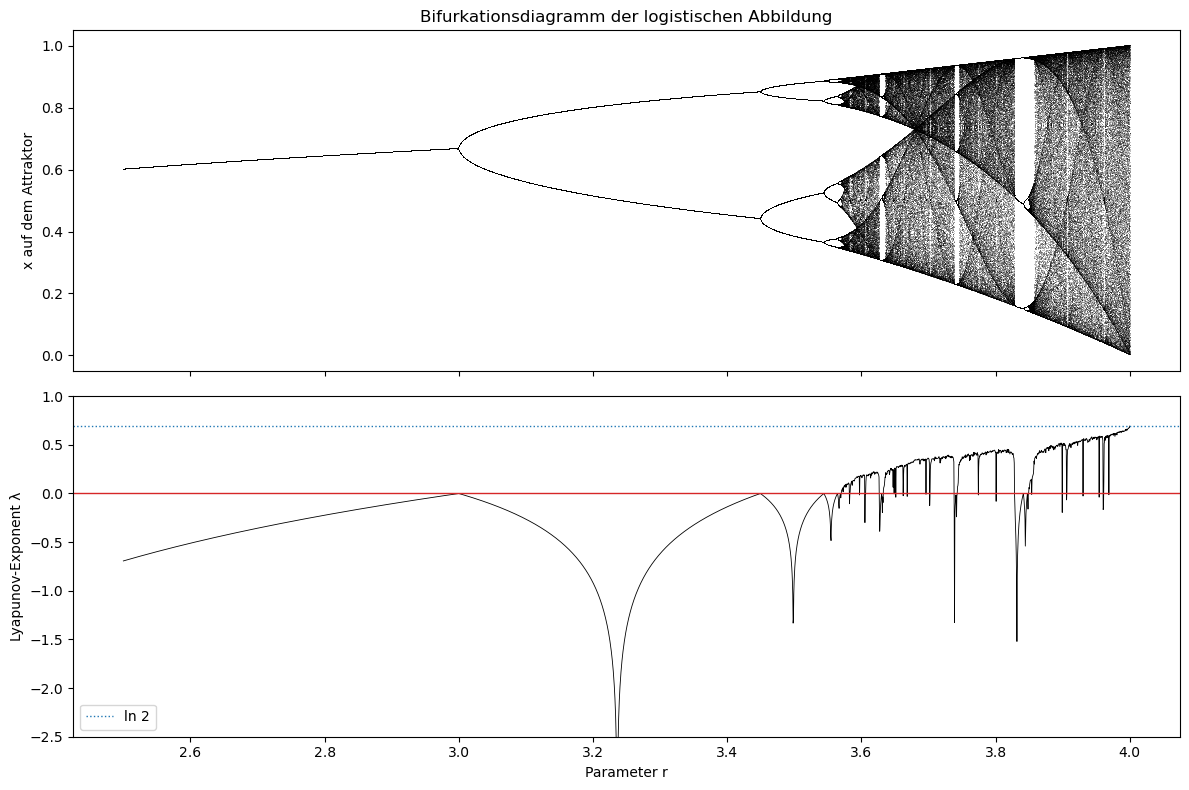

Superstabile Parameter R_n: 2.000000, 3.236068, 3.498562, 3.554641, 3.566667, 3.569244, 3.569795, 3.569913, 3.569939
Verhältnisse (R_n − R_(n−1)) / (R_(n+1) − R_n): 4.7089, 4.6808, 4.6630, 4.6684, 4.6690, 4.6692, 4.6692
Lyapunov-Exponent bei r = 4: 0.6929   (ln 2 = 0.6931)
Erstes r mit λ > 0 (Beginn des Chaos, Gitterauflösung 0.0005): 3.5704


In [3]:
rs = np.linspace(2.5, 4.0, 3000)
x = np.full_like(rs, 0.3)
for _ in range(1000):
    x = logistic(rs, x)
attractor = []
lyap = np.zeros_like(rs)
for i in range(2000):
    x = logistic(rs, x)
    lyap += np.log(np.abs(rs * (1 - 2 * x)) + 1e-300)
    if i < 300:
        attractor.append(x.copy())
lyap /= 2000
attractor = np.array(attractor)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(np.repeat(rs, 300), attractor.T.ravel(), ",", c="black", alpha=0.25)
axes[0].set_ylabel("x auf dem Attraktor")
axes[0].set_title("Bifurkationsdiagramm der logistischen Abbildung")
axes[1].plot(rs, lyap, lw=0.6, c="black")
axes[1].axhline(0, color="tab:red", lw=1)
axes[1].axhline(np.log(2), color="tab:blue", ls=":", lw=1, label="ln 2")
axes[1].set_ylim(-2.5, 1)
axes[1].set_xlabel("Parameter r")
axes[1].set_ylabel("Lyapunov-Exponent λ")
axes[1].legend()
fig.tight_layout()
plt.show()

def superstable(n, r_guess, width):
    """Parameter, bei dem x = 1/2 auf dem Zyklus der Periode 2^n liegt: F_r^(2^n)(1/2) = 1/2."""
    def g(r):
        x = 0.5
        for _ in range(2 ** n):
            x = r * x * (1 - x)
        return x - 0.5
    grid = np.linspace(r_guess - width, r_guess + width, 401)
    vals = [g(r) for r in grid]
    for a_, b_, va, vb in zip(grid[:-1], grid[1:], vals[:-1], vals[1:]):
        if va * vb < 0:
            return brentq(g, a_, b_, xtol=1e-14)

R = [2.0, 1 + np.sqrt(5)]
for n in range(2, 9):
    d = (R[-1] - R[-2]) / 4.669                           # Schätzung für den nächsten Abstand
    R.append(superstable(n, R[-1] + d, 0.3 * d))
deltas = [(R[k] - R[k - 1]) / (R[k + 1] - R[k]) for k in range(1, len(R) - 1)]
print("Superstabile Parameter R_n:", ", ".join(f"{v:.6f}" for v in R))
print("Verhältnisse (R_n − R_(n−1)) / (R_(n+1) − R_n):", ", ".join(f"{v:.4f}" for v in deltas))
print(f"Lyapunov-Exponent bei r = 4: {lyap[-1]:.4f}   (ln 2 = {np.log(2):.4f})")
print(f"Erstes r mit λ > 0 (Beginn des Chaos, Gitterauflösung {rs[1] - rs[0]:.4f}): {rs[np.argmax((lyap > 0) & (rs > 3.5))]:.4f}")

* Das **obere Bild** ist das Bifurkationsdiagramm. Bis $r = 3$ gibt es einen Ast (stabiler Fixpunkt), dann spaltet er sich in zwei (Periode 2), bei $r\approx3.449$ in vier, und die Verdopplungen folgen immer schneller aufeinander. Ab $r\approx3.57$ füllen Punktwolken ganze Bänder: Chaos. Die weißen senkrechten Streifen sind periodische Fenster, das breiteste mit Periode 3 bei $r\approx3.83$.
* Das **untere Bild** zeigt den Lyapunov-Exponenten. Im periodischen Bereich ist er negativ, an jeder Verdopplung berührt er die Null, und an den superstabilen Punkten (etwa $r = 3.236$) stürzt er nach $-\infty$. Im chaotischen Bereich ist er positiv, mit Einbrüchen in den Fenstern, und bei $r = 4$ erreicht er $\ln2$ (gepunktet).
* Die **Ausgabe** gibt die superstabilen Parameter $2, 3.236068, 3.498562, \dots, 3.569939$ und die Verhältnisse ihrer Abstände: $4.709$, $4.681$, $4.663$, $4.668$, $4.669$, $4.6692$, $4.6692$, also die Feigenbaum-Konstante. Der Lyapunov-Exponent bei $r = 4$ ist $0.6929$ ($\ln2 = 0.6931$), und das erste $r$ mit $\lambda>0$ liegt bei $3.5704$, auf Gitterauflösung am Häufungspunkt $r_\infty = 3.5699$.

##### *3. Der Schmetterlingseffekt im Lorenz-System*

Wie schnell laufen zwei Lorenz-Trajektorien auseinander, die mit einem Abstand von $10^{-9}$ starten? Vorher vorhersagen: Wie lange bleiben sie nahe beieinander, wenn der Abstand wie $e^{0.9t}$ wächst?

Beide Bahnen werden mit dem Runge-Kutta-Verfahren vierter Ordnung bis $t = 40$ integriert. Der Abstand sollte wie $e^{\lambda_1t}$ wachsen, bis er die Größe des Attraktors erreicht; die Steigung von $\ln\vert\delta\vert$ gegen $t$ in diesem Bereich ist eine erste Schätzung von $\lambda_1$.

**Hintergrund & Fachbegriffe:**
- **Lorenz-System:** drei gekoppelte Gleichungen für ein vereinfachtes Konvektionsmodell (Abschnitt 5 der Theorie). Bei $\rho = 28$ ist es chaotisch.
- **Seltsamer Attraktor:** die Menge, auf der die Bahn auf Dauer läuft; beim Lorenz-System zwei Flügel um zwei instabile Fixpunkte.
- **Empfindliche Abhängigkeit (Schmetterlingseffekt):** Kleine Unterschiede im Anfangszustand wachsen exponentiell. Der **Vorhersagehorizont** $\frac1\lambda\ln\frac{\text{Toleranz}}{\text{Anfangsfehler}}$ wächst nur logarithmisch mit der Messgenauigkeit.
- **Runge-Kutta-Verfahren:** ein Standardverfahren zum numerischen Lösen von Differentialgleichungen mit Fehler $O(\Delta t^4)$ pro Zeiteinheit.

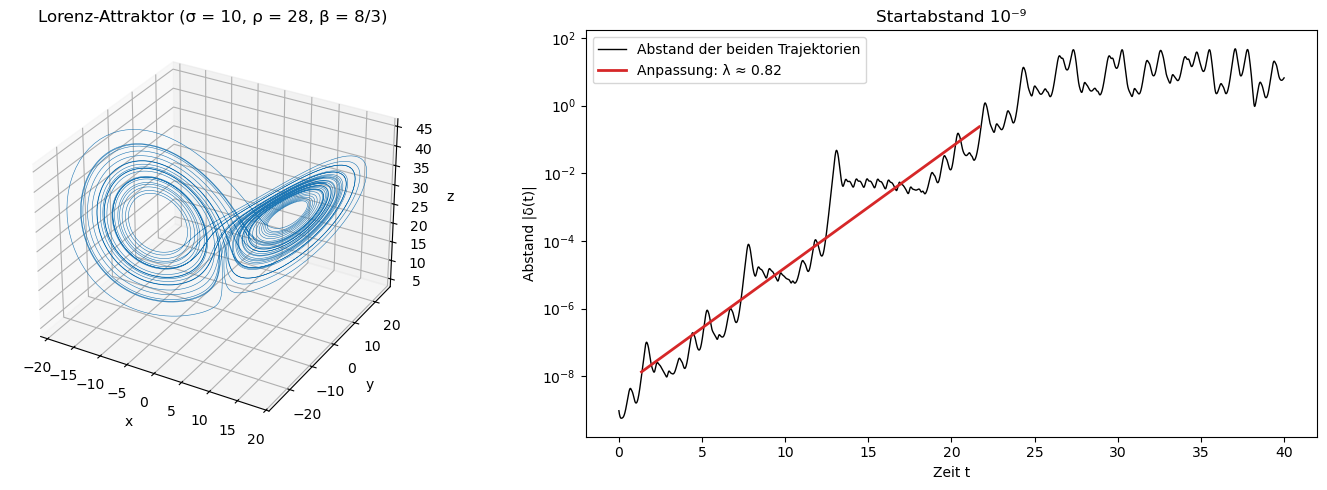

Wachstumsrate aus der Anpassung: 0.821;  Vorhersagehorizont von 10⁻⁹ bis 1: ln(10⁹)/λ ≈ 25 Zeiteinheiten


In [4]:
DT = 0.005
s = np.array([1.0, 1.0, 1.0])
for _ in range(int(20 / DT)):                         # einschwingen, bis die Bahn auf dem Attraktor ist
    s = rk4_step(lorenz, s, DT)
a_, b_ = s.copy(), s + np.array([1e-9, 0, 0])
traj_a, sep, times = [], [], []
for k in range(int(40 / DT)):
    a_, b_ = rk4_step(lorenz, a_, DT), rk4_step(lorenz, b_, DT)
    traj_a.append(a_)
    sep.append(np.linalg.norm(a_ - b_))
    times.append((k + 1) * DT)
traj_a, sep, times = np.array(traj_a), np.array(sep), np.array(times)
fit = (sep > 1e-8) & (sep < 1e-1)
slope, intercept = np.polyfit(times[fit], np.log(sep[fit]), 1)

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(*traj_a.T, lw=0.4, c="tab:blue")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.set_title("Lorenz-Attraktor (σ = 10, ρ = 28, β = 8/3)")
ax2 = fig.add_subplot(1, 2, 2)
ax2.semilogy(times, sep, c="black", lw=1, label="Abstand der beiden Trajektorien")
ax2.semilogy(times[fit], np.exp(intercept + slope * times[fit]), c="tab:red", lw=2, label=f"Anpassung: λ ≈ {slope:.2f}")
ax2.set_xlabel("Zeit t")
ax2.set_ylabel("Abstand |δ(t)|")
ax2.set_title("Startabstand 10⁻⁹")
ax2.legend()
fig.tight_layout()
plt.show()
print(f"Wachstumsrate aus der Anpassung: {slope:.3f};  Vorhersagehorizont von 10⁻⁹ bis 1: ln(10⁹)/λ ≈ {np.log(1e9) / slope:.0f} Zeiteinheiten")

* Das **linke Bild** zeigt den Lorenz-Attraktor: zwei Flügel, um die die Bahn kreist; wann sie von einem Flügel zum anderen wechselt, sieht unregelmäßig aus, obwohl die Gleichung deterministisch ist.
* Das **rechte Bild** zeigt den Abstand der beiden Bahnen auf logarithmischer Skala. Er wächst von $10^{-9}$ bis etwa $t = 25$ im Mittel exponentiell, mit unregelmäßigen Sprüngen und Plateaus, weil die Streckung auf dem Attraktor von Ort zu Ort verschieden ist. Die rote Anpassung hat die Steigung $0.82$. Danach bleibt der Abstand bei der Größe des Attraktors (einige Einheiten bis 40) stehen: Die Bahnen sind unabhängig geworden.
* Die **Ausgabe** gibt die Wachstumsrate $0.821$ und den Vorhersagehorizont $\ln(10^9)/\lambda\approx25$ Zeiteinheiten. Eine tausendmal genauere Messung brächte nur $\ln(1000)/\lambda\approx8$ Zeiteinheiten mehr.

##### *4. Das Spektrum der Lyapunov-Exponenten und die Dimension des Lorenz-Attraktors*

Welche drei Lyapunov-Exponenten hat das Lorenz-System, ist ihre Summe gleich der Divergenz $-13.67$, und welche Dimension hat der Attraktor nach Kaplan–Yorke? Vorher vorhersagen: Welcher der drei Exponenten muss null sein, und warum?

Mit dem Benettin-Verfahren aus Abschnitt 5 der Theorie werden die Bahn und drei Störungsvektoren gemeinsam integriert (Schritt 0.005), alle 10 Schritte mit einer QR-Zerlegung orthonormiert, über die Zeit $T = 500$. Gezeigt werden die laufenden Mittelwerte.

**Hintergrund & Fachbegriffe:**
- **Lyapunov-Spektrum:** In drei Dimensionen gibt es drei Exponenten: Wachstumsrate der Längen ($\lambda_1$), der Flächen ($\lambda_1 + \lambda_2$) und der Volumina ($\lambda_1 + \lambda_2 + \lambda_3$).
- **Variationsgleichung:** Eine kleine Störung $\delta x$ einer Bahn entwickelt sich nach $\dot{\delta x} = J(x(t))\,\delta x$ mit der Jacobi-Matrix entlang der Bahn.
- **QR-Zerlegung:** schreibt eine Matrix als Produkt einer orthogonalen Matrix $Q$ und einer oberen Dreiecksmatrix $R$; das ist das Gram–Schmidt-Verfahren in Matrixform. Sie hält die Störungsvektoren auseinander und misst ihr Wachstum.
- **Kaplan–Yorke-Dimension:** eine Schätzung der Dimension des Attraktors allein aus den Lyapunov-Exponenten (Abschnitt 6 der Theorie).

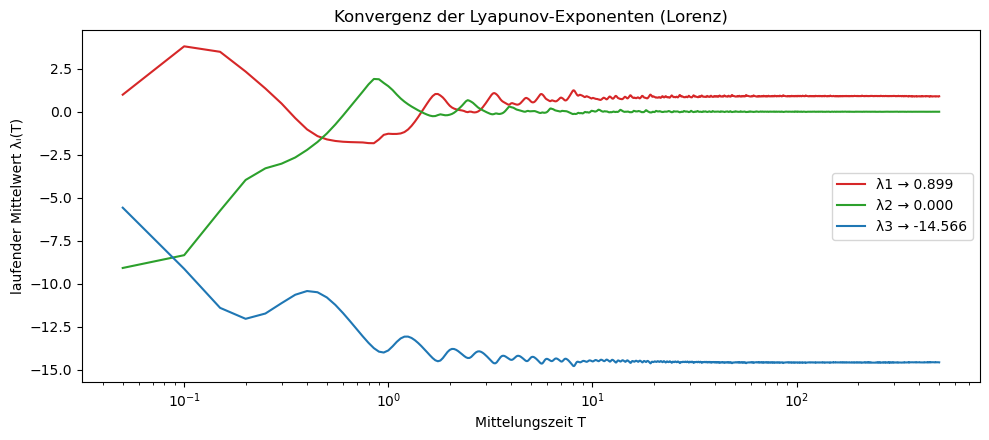

Lyapunov-Spektrum: λ1 = 0.899, λ2 = 0.000, λ3 = -14.566
Summe: -13.667   (Divergenz −σ − 1 − β = -13.667)
Kaplan-Yorke-Dimension: D = 2 + 0.899/14.566 = 2.062


In [5]:
def lorenz_with_tangent(state):
    s, W = state[:3], state[3:].reshape(3, 3)
    return np.concatenate([lorenz(s), (lorenz_jacobian(s) @ W).ravel()])

state = np.concatenate([traj_a[-1], np.eye(3).ravel()])
T_TOTAL, N_ORTHO = 500.0, 10
log_sums, history = np.zeros(3), []
n_steps = int(T_TOTAL / DT)
for k in range(1, n_steps + 1):
    state = rk4_step(lorenz_with_tangent, state, DT)
    if k % N_ORTHO == 0:
        Q, Rm = np.linalg.qr(state[3:].reshape(3, 3))
        signs = np.sign(np.diag(Rm))
        log_sums += np.log(np.abs(np.diag(Rm)))
        state[3:] = (Q * signs).ravel()
        history.append(log_sums / (k * DT))
history = np.array(history)
lam = history[-1]

j = np.max(np.nonzero(np.cumsum(lam) >= 0)[0]) + 1
D_KY = j + np.sum(lam[:j]) / abs(lam[j])

fig, ax = plt.subplots(figsize=(10, 4.5))
t_hist = np.arange(1, len(history) + 1) * N_ORTHO * DT
for i, c in enumerate(["tab:red", "tab:green", "tab:blue"]):
    ax.plot(t_hist, history[:, i], c=c, label=f"λ{i + 1} → {lam[i]:.3f}")
ax.set_xscale("log")
ax.set_xlabel("Mittelungszeit T")
ax.set_ylabel("laufender Mittelwert λᵢ(T)")
ax.set_title("Konvergenz der Lyapunov-Exponenten (Lorenz)")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Lyapunov-Spektrum: λ1 = {lam[0]:.3f}, λ2 = {lam[1]:.3f}, λ3 = {lam[2]:.3f}")
print(f"Summe: {lam.sum():.3f}   (Divergenz −σ − 1 − β = {-SIGMA - 1 - BETA:.3f})")
print(f"Kaplan-Yorke-Dimension: D = {j} + {np.sum(lam[:j]):.3f}/{abs(lam[j]):.3f} = {D_KY:.3f}")

* Das **Bild** zeigt die laufenden Mittelwerte der drei Exponenten gegen die Mittelungszeit $T$ (logarithmische Achse). Für kurze Zeiten schwanken sie stark, weil sie dann von der zufälligen Lage auf dem Attraktor abhängen; ab etwa $T = 10$ liegen sie fest: $\lambda_1\to0.899$ (rot), $\lambda_2\to0.000$ (grün), $\lambda_3\to-14.566$ (blau).
* Die **Ausgabe** bestätigt: Die Summe ist $-13.667$, genau die Divergenz $-\sigma - 1 - \beta$. $\lambda_2$ ist null, wie bei jedem Fluss, weil eine Störung entlang der Bahn nur eine Zeitverschiebung ist. In der Literatur steht meist $0.906$, $0$, $-14.57$; der kleine Unterschied bei $\lambda_1$ kommt von der endlichen Mittelungszeit.
* Die **Kaplan–Yorke-Dimension** ist $2 + 0.899/14.566 = 2.062$: Der Attraktor ist etwas mehr als eine Fläche. In zwei Richtungen wird nicht geschrumpft (eine streckt, eine ist neutral), die dritte wird so stark zusammengedrückt, dass nur 6 % von ihr übrig bleiben.

##### *5. Fraktale Dimension: Kochkurve und Hénon-Attraktor*

Misst Box-Counting an der Kochkurve die bekannte Dimension $\ln4/\ln3$, und stimmt beim Hénon-Attraktor die Box-Counting-Dimension mit der Kaplan–Yorke-Dimension aus den Lyapunov-Exponenten überein? Vorher vorhersagen: Wie viele Kästchen braucht die Kochkurve mehr, wenn man die Kästchen dreimal kleiner macht?

Für die Kochkurve (7. Stufe, mit 20 Zwischenpunkten pro Strecke) sind die Kästchen $\varepsilon = 3^{-k}$ groß, passend zu ihrer Selbstähnlichkeit: Bei beliebigen $\varepsilon$ schwankt $N(\varepsilon)$ periodisch in $\ln(1/\varepsilon)$, und eine Anpassung über einen beliebigen Bereich verschiebt die Steigung. Das Gitter ist leicht verschoben, sonst lägen die Ecken der Kurve genau auf Kästchenrändern und würden doppelt gezählt. Für den Hénon-Attraktor werden 400 000 Punkte erzeugt, die Lyapunov-Exponenten mit QR-Zerlegungen über 100 000 Schritte bestimmt und Kästchen von $10^{-3}$ bis $10^{-1}$ gezählt.

**Hintergrund & Fachbegriffe:**
- **Selbstähnlichkeit:** Ein Teil der Menge sieht vergrößert aus wie das Ganze. Die Kochkurve besteht aus vier Kopien ihrer selbst, jede um den Faktor 3 verkleinert.
- **Box-Counting:** Man legt ein Gitter aus Kästchen der Größe $\varepsilon$ über die Menge und zählt, wie viele belegt sind. Wächst die Zahl wie $\varepsilon^{-D}$, ist $D$ die Dimension; im doppelt logarithmischen Bild ist sie die Steigung.
- **Hénon-Abbildung:** $x_{n+1} = 1 - ax_n^2 + y_n$, $y_{n+1} = bx_n$; bei $a = 1.4$, $b = 0.3$ hat sie einen seltsamen Attraktor.
- **Jacobi-Determinante:** der Faktor, um den sich kleine Flächen pro Schritt ändern; bei Hénon überall $-b$, also schrumpfen Flächen um den Faktor 0.3, und $\lambda_1 + \lambda_2 = \ln0.3$.

Kochkurve: N(ε) = [19, 75, 303, 1212, 4726]


Hénon: N(ε) = [7546, 4084, 2183, 1163, 627, 326, 171, 94, 50, 27]


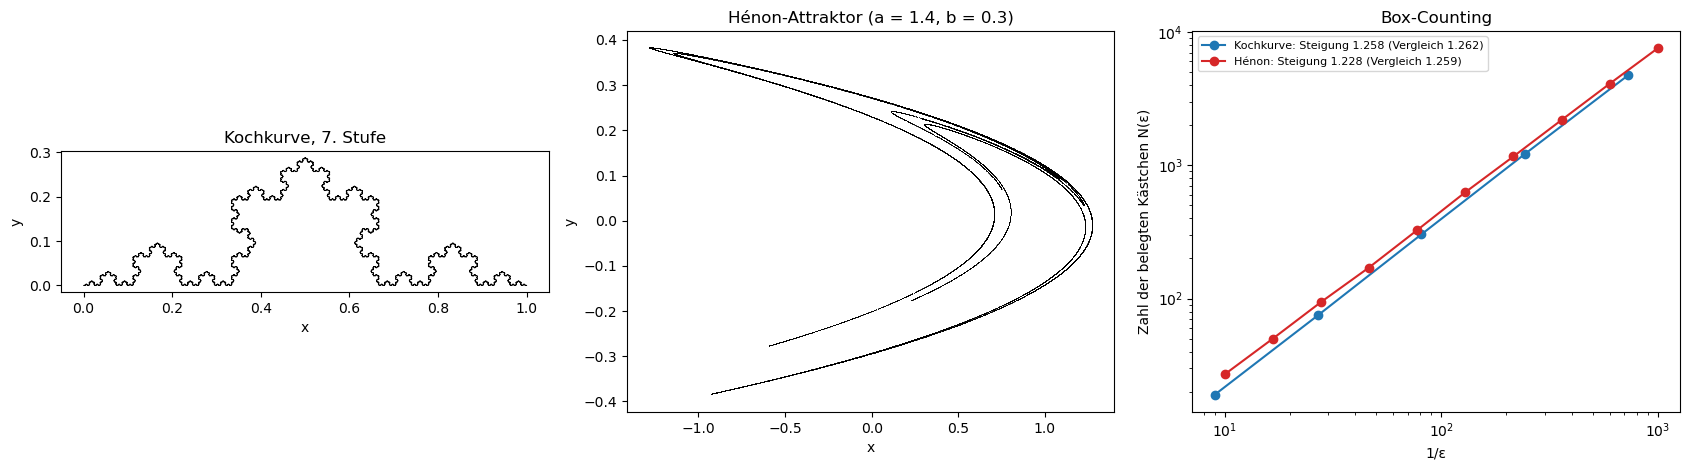

Kochkurve: Box-Counting 1.258, exakt ln4/ln3 = 1.2619
Hénon: λ1 = 0.420, λ2 = -1.624 (Summe -1.204, ln 0.3 = -1.204); Kaplan-Yorke 1.259, Box-Counting 1.228


In [6]:
def koch(level):
    pts = np.array([[0.0, 0.0], [1.0, 0.0]])
    rot = np.array([[0.5, -np.sqrt(3) / 2], [np.sqrt(3) / 2, 0.5]])          # Drehung um 60°
    for _ in range(level):
        new = [pts[0]]
        for p, q in zip(pts[:-1], pts[1:]):
            d = (q - p) / 3
            new += [p + d, p + d + rot @ d, p + 2 * d, q]
        pts = np.array(new)
    return pts

def densify(pts, n=20):
    """Zusätzliche Punkte auf jeder Strecke, damit kleine Kästchen die Kurve nicht verfehlen."""
    s = np.linspace(0, 1, n, endpoint=False)[:, None, None]
    return (pts[:-1] + s * (pts[1:] - pts[:-1])).reshape(-1, 2)

koch_pts = densify(koch(7))

A_H, B_H = 1.4, 0.3
N_H = 400_000
hen = np.empty((N_H, 2))
x, y = 0.1, 0.1
for _ in range(1000):
    x, y = 1 - A_H * x * x + y, B_H * x
log_sums, v = np.zeros(2), np.eye(2)
for i in range(N_H):
    x, y = 1 - A_H * x * x + y, B_H * x
    hen[i] = x, y
    Q, Rm = np.linalg.qr(np.array([[-2 * A_H * x, 1.0], [B_H, 0.0]]) @ v) if i < 100_000 else (None, None)
    if Q is not None:
        log_sums += np.log(np.abs(np.diag(Rm)))
        v = Q
lam_h = log_sums / 100_000
D_KY_h = 1 + lam_h[0] / abs(lam_h[1])

eps_sets = {"Kochkurve": 3.0 ** -np.arange(2, 7), "Hénon": np.logspace(-3, -1, 10)}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].plot(*koch(7).T, lw=0.5, c="black")                     # die Kurve selbst; koch_pts enthält sie 20-mal versetzt
axes[0].set_aspect("equal")
axes[0].set_title("Kochkurve, 7. Stufe")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[1].plot(*hen[:50_000].T, ",", c="black", alpha=0.5)
axes[1].set_title(f"Hénon-Attraktor (a = {A_H}, b = {B_H})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("y")
results = {}
for name, pts, c, ref in [("Kochkurve", koch_pts, "tab:blue", np.log(4) / np.log(3)), ("Hénon", hen, "tab:red", D_KY_h)]:
    eps = eps_sets[name]
    N_eps = box_counting(pts, eps)
    slope = np.polyfit(np.log(1 / eps), np.log(N_eps), 1)[0]
    results[name] = slope
    print(f"{name}: N(ε) = {N_eps.tolist()}")
    axes[2].loglog(1 / eps, N_eps, "o-", c=c, label=f"{name}: Steigung {slope:.3f} (Vergleich {ref:.3f})")
axes[2].set_xlabel("1/ε")
axes[2].set_ylabel("Zahl der belegten Kästchen N(ε)")
axes[2].set_title("Box-Counting")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Kochkurve: Box-Counting {results['Kochkurve']:.3f}, exakt ln4/ln3 = {np.log(4) / np.log(3):.4f}")
print(f"Hénon: λ1 = {lam_h[0]:.3f}, λ2 = {lam_h[1]:.3f} (Summe {lam_h.sum():.3f}, ln 0.3 = {np.log(0.3):.3f}); "
      f"Kaplan-Yorke {D_KY_h:.3f}, Box-Counting {results['Hénon']:.3f}")

* Das **linke Bild** zeigt die Kochkurve in der 7. Stufe, das **mittlere** den Hénon-Attraktor: ein gebogenes Band, das bei Vergrößerung aus vielen dünnen, parallelen Schichten besteht, die sich bei jeder Anwendung der Abbildung strecken und falten.
* Das **rechte Bild** zeigt die Zahl der belegten Kästchen gegen $1/\varepsilon$, doppelt logarithmisch. Beide Mengen liegen auf Geraden; die Kochkurve hat die Steigung $1.258$ (exakt $\ln4/\ln3 = 1.262$), der Hénon-Attraktor $1.228$ (Kaplan–Yorke $1.259$). Beide Dimensionen liegen zwischen 1 und 2: mehr als eine Kurve, weniger als eine Fläche.
* Die **Ausgabe** gibt für Hénon $\lambda_1 = 0.420$ und $\lambda_2 = -1.624$, mit der Summe $-1.204 = \ln0.3$ wie vorhergesagt, und die Kaplan–Yorke-Dimension $1 + 0.420/1.624 = 1.259$. Box-Counting liefert weniger, $1.228$: Der Attraktor besteht aus Schichten sehr ungleicher Dichte, und die Steigung erreicht ihren Grenzwert erst bei viel kleineren Kästchen als hier.

#### **Ergebnis**

Beim Lauf vom 2026-10-12:

- **Pendel:** Am Fixpunkt $\theta = 0$ hat die Jacobi-Matrix die Eigenwerte $-0.15 \pm 0.99i$ (stabile Spirale), bei $\theta = \pi$ die Eigenwerte $0.86$ und $-1.16$ (Sattel). Die Energie fällt entlang jeder gedämpften Bahn monoton; sie ist eine Lyapunov-Funktion, und der Fixpunkt ist stabil, ohne dass man die Gleichung lösen muss.
- **Logistische Abbildung:** Die Verhältnisse der Abstände der superstabilen Parameter konvergieren gegen $4.6692$, die Feigenbaum-Konstante. Der Lyapunov-Exponent wird ab $r \approx 3.570$ positiv (Häufungspunkt der Verdopplungen $r_\infty = 3.5699$), mit Fenstern periodischen Verhaltens ($\lambda < 0$) dazwischen, und bei $r = 4$ ist er $0.693 = \ln 2$.
- **Schmetterlingseffekt:** Ein Startabstand von $10^{-9}$ wächst im Mittel wie $e^{0.82\,t}$ und erreicht nach etwa 25 Zeiteinheiten die Größe des Attraktors; danach sind die beiden Bahnen unabhängig. Das Wachstum ist ungleichmäßig, weil die Streckung auf dem Attraktor von Ort zu Ort verschieden ist; der Mittelwert über lange Zeiten ist der Lyapunov-Exponent.
- **Lyapunov-Spektrum (Lorenz):** $\lambda_1 = 0.899$, $\lambda_2 = 0.000$, $\lambda_3 = -14.566$ (in der Literatur meist $0.906$, $0$, $-14.57$). Die Summe ist $-13.667$, genau die Divergenz $-\sigma - 1 - \beta$. Die Kaplan-Yorke-Dimension ist $2.062$: Der Attraktor ist etwas mehr als eine Fläche.
- **Fraktale Dimension:** Kochkurve $1.258$ (exakt $\ln 4/\ln 3 = 1.262$). Hénon-Attraktor: $\lambda_1 = 0.420$, $\lambda_2 = -1.624$, Summe genau $\ln 0.3$; Kaplan-Yorke-Dimension $1.259$. Box-Counting gibt nur $1.23$, auch mit 4 Millionen Punkten. Mathematisch ist die Box-Counting-Dimension mindestens so groß wie die Kaplan-Yorke-Dimension; die Anpassung unterschätzt sie also. Der Attraktor besteht aus Schichten sehr ungleicher Dichte, und die Steigung erreicht ihren Grenzwert erst bei viel kleineren Kästchen als hier.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Lorenz unterhalb des Chaos:** Setze $\rho = 20$. *(Vorhersage: Die Bahn spiralt in einen der beiden Fixpunkte $(\pm\sqrt{\beta(\rho - 1)}, \pm\sqrt{\beta(\rho - 1)}, \rho - 1)$; der größte Lyapunov-Exponent wird negativ.)*
2. **Fenster der Periode 3:** Im Bifurkationsdiagramm liegt bei $r \approx 3.83$ ein Fenster mit Periode 3 mitten im Chaos. Welches Vorzeichen hat dort $\lambda$, und was passiert am Rand des Fensters?
3. **Angetriebenes Pendel:** Füge der Pendelgleichung einen periodischen Antrieb $A\cos(\Omega t)$ hinzu ($\gamma = 0.5$, $\Omega = 2/3$, $A = 1.2$). Der Phasenraum wird dreidimensional (Zeit als dritte Koordinate), und Chaos wird möglich. Zeichne einen Poincaré-Schnitt: den Zustand jeweils bei $t = 2\pi k/\Omega$.
4. **Hénon mit kleinerem $a$:** Setze $a = 1.0$. Was wird aus dem Attraktor, und was aus $\lambda_1$?
5. **Vorhersagehorizont:** Wie viel länger kann man das Lorenz-System vorhersagen, wenn der Anfangsfehler von $10^{-9}$ auf $10^{-12}$ sinkt? *(Vorhersage: nur um $\ln(1000)/\lambda_1 \approx 7.6$ Zeiteinheiten.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum können sich Trajektorien eines Flusses nicht schneiden, und was folgt daraus für Chaos in der Ebene?</summary>

Weil die Lösung zu jedem Startpunkt eindeutig ist (Picard–Lindelöf): Im Schnittpunkt hätten zwei Bahnen dieselbe Zukunft. In der Ebene bleibt einer beschränkten Bahn deshalb nur ein Fixpunkt oder ein Zyklus (Poincaré–Bendixson); Chaos braucht in Flüssen drei Dimensionen, bei Abbildungen reicht eine.
</details>

<details><summary>2. Wie entscheidet man über die Stabilität eines Fixpunkts?</summary>

Über die Eigenwerte der Jacobi-Matrix: alle Realteile negativ heißt stabil, einer positiv instabil; komplex gibt Spiralen, reell mit verschiedenen Vorzeichen einen Sattel. Oder mit einer Lyapunov-Funktion, die entlang der Bahnen nicht zunimmt. Bei Abbildungen zählt, ob $\vert F'\vert<1$ ist.
</details>

<details><summary>3. Warum ist die Energie des gedämpften Pendels eine Lyapunov-Funktion?</summary>

$V = \tfrac12\dot\theta^2 + 1 - \cos\theta$ ist im Fixpunkt null und sonst positiv, und entlang der Bahnen ist $\dot V = -\gamma\dot\theta^2\leq0$.
</details>

<details><summary>4. Was passiert bei einer Periodenverdopplung, und was misst die Feigenbaum-Konstante?</summary>

Die Ableitung am Zyklus erreicht $-1$, der Zyklus wird instabil, und ein Zyklus doppelter Periode übernimmt. Die Abstände aufeinanderfolgender Verdopplungen schrumpfen um den Faktor $\delta = 4.6692$, gleich für alle Abbildungen mit quadratischem Maximum; sie häufen sich bei $r_\infty\approx3.5699$.
</details>

<details><summary>5. Was ist ein Lyapunov-Exponent, und wie berechnet man ihn für eine Abbildung?</summary>

Die mittlere exponentielle Wachstumsrate kleiner Störungen. Für eine Abbildung ist er der Mittelwert von $\ln\vert F'(x_k)\vert$ entlang der Bahn; positiv heißt Chaos.
</details>

<details><summary>6. Warum ist der Lyapunov-Exponent der logistischen Abbildung bei r = 4 genau ln 2?</summary>

Mit $x = \sin^2(\pi y/2)$ wird sie zur Zeltabbildung mit Steigung vom Betrag 2; pro Schritt verdoppelt sich ein kleiner Fehler im Mittel, ein Bit Information geht verloren.
</details>

<details><summary>7. Wie lange kann man ein chaotisches System vorhersagen?</summary>

Etwa $\frac1\lambda\ln\frac{\text{Toleranz}}{\text{Anfangsfehler}}$. Beim Lorenz-System mit $\lambda\approx0.9$ und Anfangsfehler $10^{-9}$ rund 25 Zeiteinheiten; tausendmal genauer bringt nur 8 mehr.
</details>

<details><summary>8. Warum ist die Summe der Lyapunov-Exponenten des Lorenz-Systems −13.67, und warum ist einer null?</summary>

Die Summe ist die mittlere Wachstumsrate von Volumina, also die Divergenz $\nabla\cdot f = -\sigma - 1 - \beta$. Null ist der Exponent der Richtung entlang der Bahn: Eine Störung dort ist nur eine Zeitverschiebung.
</details>

<details><summary>9. Wozu braucht das Benettin-Verfahren QR-Zerlegungen?</summary>

Ohne sie würden alle Störungsvektoren in die Richtung des stärksten Wachstums kippen. Die QR-Zerlegung hält sie orthogonal, und die Diagonale von $R$ gibt das Wachstum jeder Richtung.
</details>

<details><summary>10. Wie kann ein Attraktor das Volumen null haben und trotzdem Bahnen auseinandertreiben?</summary>

Er wird in einer Richtung gestreckt und in einer anderen gefaltet und zusammengedrückt, immer wieder. Es entsteht ein Fraktal: Struktur auf allen Skalen, nicht ganzzahlige Dimension.
</details>

<details><summary>11. Was misst die Box-Counting-Dimension, und welchen Wert hat sie für die Kochkurve?</summary>

Wie die Zahl der Kästchen, die man zum Bedecken braucht, mit ihrer Größe wächst: $N\propto\varepsilon^{-D}$. Bei der Kochkurve gibt dreimal kleinere Kästchen viermal so viele, also $D = \ln4/\ln3 = 1.262$.
</details>

<details><summary>12. Was sagt die Kaplan–Yorke-Dimension, und welche Werte hat sie für Lorenz und Hénon?</summary>

$D_{KY} = j + (\lambda_1 + \dots + \lambda_j)/\vert\lambda_{j+1}\vert$, eine Dimension allein aus den Lyapunov-Exponenten: 2.06 für Lorenz, 1.26 für Hénon.
</details>

#### **Nächste Schritte**

- **Zeitreihen:** Aus einer einzigen gemessenen Größe lässt sich der Attraktor rekonstruieren (Einbettung mit Zeitverzögerung, Satz von Takens), und daraus Dimension (Korrelationsdimension nach Grassberger und Procaccia) und Lyapunov-Exponenten schätzen.
- **Quantenchaos:** Quantensysteme haben keine Trajektorien. Ihr Gegenstück zum Lyapunov-Exponenten ist das exponentielle Wachstum von Kommutatoren (OTOC, siehe `quantum/chaos_scrambling.ipynb`), und ihr Fingerabdruck von Chaos ist die Statistik der Energieniveaus (Notebook `randommatrices.ipynb`).
- **Netzwerke gekoppelter Oszillatoren:** Synchronisation im Kuramoto-Modell (Notebook `complexnetworks.ipynb`).
- **Turbulenz und Wetter:** Ensemble-Vorhersagen nutzen genau den Schmetterlingseffekt: Man rechnet viele leicht gestörte Anfangszustände und liest aus ihrer Streuung ab, wie verlässlich die Vorhersage ist.

#### **Referenzen**

- Strogatz, S. H. (2015): *Nonlinear Dynamics and Chaos*, 2nd ed., Westview Press; Kap. 6 (Phasenebene), 9 (Lorenz), 10 (Abbildungen, logistische Abbildung, Lyapunov-Exponent), 11 (Fraktale).
- Ott, E. (2002): *Chaos in Dynamical Systems*, 2nd ed., Cambridge University Press.
- Lorenz, E. N. (1963): *Deterministic Nonperiodic Flow*, J. Atmos. Sci. 20, 130.
- Feigenbaum, M. J. (1978): *Quantitative universality for a class of nonlinear transformations*, J. Stat. Phys. 19, 25.
- Hénon, M. (1976): *A two-dimensional mapping with a strange attractor*, Commun. Math. Phys. 50, 69.
- Benettin, G., Galgani, L., Giorgilli, A. & Strelcyn, J.-M. (1980): *Lyapunov characteristic exponents for smooth dynamical systems and for Hamiltonian systems*, Meccanica 15, 9.
- Kaplan, J. L. & Yorke, J. A. (1979): *Chaotic behavior of multidimensional difference equations*, Lecture Notes in Mathematics 730, 204.
- Grassberger, P. & Procaccia, I. (1983): *Measuring the strangeness of strange attractors*, Physica D 9, 189.